# 28. A sculpture in a smaller packet

[Course plan](../../README.md)

The held-out photograph already reveals the limits of 117 splats. The edges of the sculpture are slightly soft. A smaller file can introduce another kind of error. Both images here share the same camera. The reference is the uncompressed render so that errors from fitting and packing stay separate.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "en"

## The first eight bytes

The file begins with four ordinary bytes spelling `GSC1`. The next byte records the bytes per parameter. Another gives the number of color channels. The last two encode the splat count, low byte first. For 117 splats these bytes are 117 and 0 because $117+256\cdot0=117$. The header occupies $4+1+1+2=8$ bytes.

With constant RGB each splat has 14 numbers in this order: center, widths, quaternion, opacity, color. With float32 throughout, the file takes $8+117\cdot14\cdot4=6560$ bytes. Converting the original double-precision numbers to float32 already rounds the least significant digits.

In [2]:
scene, frames = codec.photo_data()
raw = codec.pack_static(scene, 'f32')
print(raw[:8], list(raw[4:8]), len(raw))
decoded = codec.unpack_static(raw)
print('x:', scene['splats'][0]['center'][0], '→', decoded['splats'][0]['center'][0])

b'GSC1\x04\x03u\x00' [4, 3, 117, 0] 6560
x: 1.4339829476167152 → 1.4339829683303833


## One byte for a coordinate

Suppose $x=1.5$ m falls between $a=1$ and $b=3$ m. The span $b-a$ is 2 m. The fraction of the distance from the left edge is $(1.5-1)/2=0.25$, with the meters cancelling. Eight bits give $2^8=256$ codes, from 0 through 255. There are 255 gaps between them. A fraction of 0.25 lands at $0.25\cdot255=63.75$. The nearest code is 64. On decoding, $64/255\approx0.25098$. Converting back gives $1+2\cdot64/255\approx1.50196$ m, a shift of about two millimeters.

$$
q=\left\lfloor255\frac{x-a}{b-a}+0.5\right\rfloor,\qquad \hat{x}=a+(b-a)\frac{q}{255}.
$$

Here $q$ is the integer code. The floor drops the fractional part after adding one half. The hat on $\hat{x}$ marks a reconstructed value. If the endpoints coincide, code zero decodes to that endpoint. Three coordinates and three widths each need their own pair of bounds. Twelve float32 values add $12\cdot4=48$ bytes. Each component of a normalized quaternion lies between −1 and 1. Color and opacity lie between 0 and 1. Those bounds are already known. The renderer normalizes the decoded quaternion when it converts it to a rotation matrix.

The entire scene now takes $8+48+117\cdot14=1694$ bytes. For a single splat the extra bounds can consume all the savings.

In [3]:
display(demos.codec_lab(28, lang))

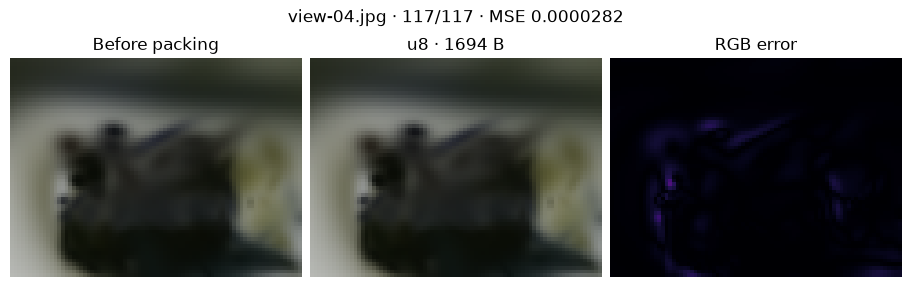

In [4]:
demos.static_figure(lang)
plt.show()

## Which splats can go?

Two splats have the same two longest widths, 0.4 and 0.2 m. At opacity 0.8 the first receives a score of $0.8\cdot0.4\cdot0.2=0.064$ square meters. At opacity 0.1 the second scores only 0.008. We retain the larger products. This is a cheap guess at how much image area a splat may influence. It omits camera distance, occlusion and contrast with the background. A tiny bright highlight against a dark surface can disappear. Sorting only decides which splats survive. Their rows stay in the original order.

At a retention of 50%, half of 117 is 58.5. Rounding upward leaves 59 splats and $56+59\cdot14=882$ bytes. Color offers a separate lever. A color such as $(0.9,0.3,0)$ has mean $(0.9+0.3+0)/3=0.4$. The decoder can store that single value and return $(0.4,0.4,0.4)$. This teaching average gives each channel equal weight. One code in place of three saves two bytes per splat, but red and green with the same mean become indistinguishable.

f32-rgb 6560 B; MSE 0.0 frame ms 118.847


u8-rgb 1694 B; MSE 2.82e-05 frame ms 86.912
u8-half 882 B; MSE 0.0043138 frame ms 33.896


u8-gray-half 764 B; MSE 0.0046234 frame ms 31.714


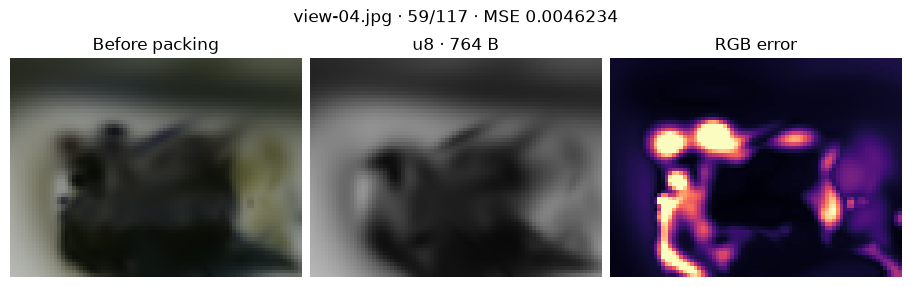

In [5]:
ref = render_scene(scene, frames['view-04.jpg']['camera'], 80, 60)
for name, precision, keep, color in codec.static_candidates():
    data = codec.pack_static(scene, precision, keep, color)
    model = codec.unpack_static(data)
    def draw():
        return render_scene(model, frames['view-04.jpg']['camera'], 80, 60)
    print(name, len(data), 'B; MSE', round(scores(draw(), ref)['mse'], 7),
          'frame ms', round(benchmark(draw, repeats=3), 3))
demos.static_figure(lang, keep=50, color='gray')
plt.show()

## Reading the comparison

The error maps keep the same scale from 0 to 0.2. Each map pixel is the mean of the three absolute channel differences. The MSE in the title averages their **squares** over every pixel and channel. Timing begins with a warm-up, then uses the median of repeated renders. The browser batches short calls and divides elapsed time by the batch count. Every packet decodes into the same kind of scene. Switching to uint8 does not by itself reduce the number of blends. Removing 58 splats does.

**Experiment.** How many bytes do 59 gray uint8 splats take? What would the same color change save with float32?

<details>
<summary>Worked answer</summary>

A gray splat has 12 fields, for $56+59\cdot12=764$ bytes. Color used $882-764=118$ more bytes. In float32 the difference would be $59\cdot2\cdot4=472$ bytes. Both changes remove hue.

</details>